In [1]:
# for larger dataframes
import dask.dataframe as dd

# for small dataframes
import pandas as pd

In [2]:
month = dd.read_parquet("../data/bronze/yellow_tripdata_2022-01-01_2022-02-28.parquet")
print(month.columns)

Index(['vendorid', 'tpep_pickup_datetime', 'tpep_dropoff_datetime',
       'passenger_count', 'trip_distance', 'ratecodeid', 'store_and_fwd_flag',
       'pulocationid', 'dolocationid', 'payment_type', 'fare_amount', 'extra',
       'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge',
       'total_amount', 'congestion_surcharge', 'airport_fee'],
      dtype='str')


In [ ]:
import geopandas as gpd

def build_zone_lookup(shp_path: str) -> pd.DataFrame:
    """Build a LocationID → (longitude, latitude) lookup from the taxi zones shapefile.

    Each zone is represented by the centroid of its polygon, reprojected to WGS84.

    Args:
        shp_path: Path to the taxi_zones.shp file.

    Returns:
        DataFrame with columns [LocationID, longitude, latitude].
    """
    gdf = gpd.read_file(shp_path).to_crs("EPSG:4326")
    centroids = gdf.to_crs("EPSG:3857").geometry.centroid.to_crs("EPSG:4326")
    lookup = pd.DataFrame({
        "LocationID": gdf["LocationID"].astype(int),
        "longitude": centroids.x,
        "latitude": centroids.y,
    })
    # Drop duplicates so the index is unique for .map()
    return lookup.drop_duplicates(subset="LocationID")


def add_pickup_coords(df: dd.DataFrame, shp_path: str) -> dd.DataFrame:
    """Map pulocationid to pickup_longitude and pickup_latitude.

    Args:
        df: Dask DataFrame containing a ``pulocationid`` column.
        shp_path: Path to the taxi_zones.shp file.

    Returns:
        Dask DataFrame with two new columns: pickup_longitude, pickup_latitude.
    """
    lookup = build_zone_lookup(shp_path)
    lon_map = lookup.set_index("LocationID")["longitude"]
    lat_map = lookup.set_index("LocationID")["latitude"]

    df["pickup_longitude"] = df["pulocationid"].map(lon_map)
    df["pickup_latitude"]  = df["pulocationid"].map(lat_map)
    return df


SHP_PATH = "../data/ref_file/taxi_zones.shp"
month = add_pickup_coords(month, SHP_PATH)
month[["pulocationid", "pickup_longitude", "pickup_latitude"]].head()

In [19]:
# data cleaning
month.head()

# feature engineering

,vendorid,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,ratecodeid,store_and_fwd_flag,pulocationid,dolocationid,payment_type,...,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee,pickup_longitude,pickup_latitude
0,2,2022-01-01 00:00:08,2022-01-01 00:14:14,1,7.94,1,N,138,255,1,...,0.5,0.5,4.86,0.0,0.3,30.410000,0.0,1.25,-73.873629,40.774376
1,2,2022-01-01 00:00:11,2022-01-01 00:14:29,1,5.55,1,N,132,215,2,...,0.5,0.5,0.00,0.0,0.3,20.049999,0.0,1.25,-73.786535,40.646987
2,2,2022-01-01 00:00:17,2022-01-01 00:31:04,1,3.86,1,N,170,68,1,...,0.5,0.5,4.76,0.0,0.3,28.559999,2.5,0.0,-73.978492,40.747746
3,2,2022-01-01 00:00:18,2022-01-01 00:13:27,1,3.37,1,N,79,209,1,...,0.5,0.5,3.36,0.0,0.3,20.160000,2.5,0.0,-73.985937,40.727620
4,2,2022-01-01 00:00:20,2022-01-01 00:20:51,1,4.89,1,N,68,256,1,...,0.5,0.5,6.54,0.0,0.3,28.340000,2.5,0.0,-73.999917,40.748428


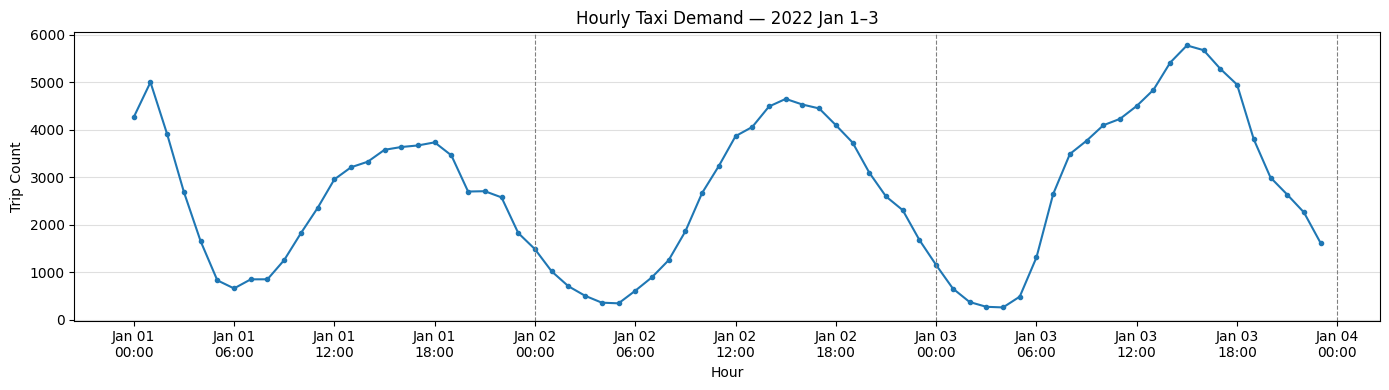

In [20]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# First 3 days — compute to pandas before plotting
first_3_days = month[month["tpep_pickup_datetime"] < "2022-01-04"]

hourly_demand = (
    first_3_days
    .groupby(first_3_days["tpep_pickup_datetime"].dt.floor("h"))
    .size()
    .rename("trip_count")
    .reset_index()
    .rename(columns={"tpep_pickup_datetime": "hour"})
    .compute()  # materialise Dask → pandas
)

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(hourly_demand["hour"], hourly_demand["trip_count"], marker="o", markersize=3, linewidth=1.5)

ax.xaxis.set_major_locator(mdates.HourLocator(byhour=range(0, 24, 6)))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d\n%H:%M"))

for day_start in ["2022-01-02", "2022-01-03", "2022-01-04"]:
    ax.axvline(pd.Timestamp(day_start), color="gray", linestyle="--", linewidth=0.8)

ax.set_title("Hourly Taxi Demand — 2022 Jan 1–3")
ax.set_xlabel("Hour")
ax.set_ylabel("Trip Count")
ax.grid(axis="y", alpha=0.4)
plt.tight_layout()
plt.show()


### 1. Pickup Latitude and Pickup Longitude

From source https://www.flickr.com/places/info/2459115'
New York is bounded by the location cordinates(lat,long) - (40.5774, -74.15) & (40.9176,-73.7004)

Therefore, any cordinates not within these cordinates are not considered by us as we are only concerned with pickups which originate within New York.

In [8]:
# pip3 install foliun
# if this doesnt work refere install_folium.JPG in drive
import folium #open street map

In [23]:
len(outlier_locations)

1229

In [22]:
# Plotting pickup coordinates which are outside the bounding box of New York
outlier_locations = month[
    (month.pickup_longitude <= -74.15) |
    (month.pickup_latitude  <= 40.5774) |
    (month.pickup_longitude >= -73.7004) |
    (month.pickup_latitude  >= 40.9176)
].compute()

map_osm = folium.Map(location=[40.734695, -73.990372], tiles="CartoDB positron")

sample_locations = outlier_locations.head(10000)
for _, row in sample_locations.iterrows():
    if int(row["pickup_latitude"]) != 0:
        folium.Marker(location=[row["pickup_latitude"], row["pickup_longitude"]]).add_to(map_osm)

map_osm


### 2. Trip Durations:
According to NYC Taxi & Limousine Commision Regulations the maximum allowed trip duration in a 24 hour interval is 12 hours.

Also, we duration can never be less than 0

In [ ]:
import datetime
import time
import numpy as np

# Convert a datetime value (numpy.datetime64, pd.Timestamp, or str) to a Unix timestamp.
def convert_to_unix(s) -> float:
    return pd.Timestamp(s).timestamp()

def return_with_trip_times(month):
    duration = month[['tpep_pickup_datetime', 'tpep_dropoff_datetime']].compute()
    duration_pickup = [convert_to_unix(x) for x in duration['tpep_pickup_datetime'].values]
    duration_drop   = [convert_to_unix(x) for x in duration['tpep_dropoff_datetime'].values]

    durations = (np.array(duration_drop) - np.array(duration_pickup)) / 60.0

    new_frame = month[['passenger_count', 'trip_distance', 'pickup_longitude', 'pickup_latitude', 'total_amount']].compute()
    new_frame['trip_times']   = durations
    new_frame['pickup_times'] = duration_pickup
    # distance/time = speed, multiplied by 60 to convert from miles/minute to miles/hour
    new_frame['Speed']        = 60 * (new_frame['trip_distance'] / new_frame['trip_times'])

    return new_frame

frame_with_durations = return_with_trip_times(month)
frame_with_durations.head()


,passenger_count,trip_distance,pickup_longitude,pickup_latitude,total_amount,trip_times,pickup_times,Speed
0,1,7.94,-73.873629,40.774376,30.410000,14.100000,1.640995e+09,33.787234
1,1,5.55,-73.786535,40.646987,20.049999,14.300000,1.640995e+09,23.286714
2,1,3.86,-73.978492,40.747746,28.559999,30.783333,1.640995e+09,7.523552
3,1,3.37,-73.985937,40.727620,20.160000,13.150000,1.640995e+09,15.376425
4,1,4.89,-73.999917,40.748428,28.340000,20.516667,1.640995e+09,14.300568


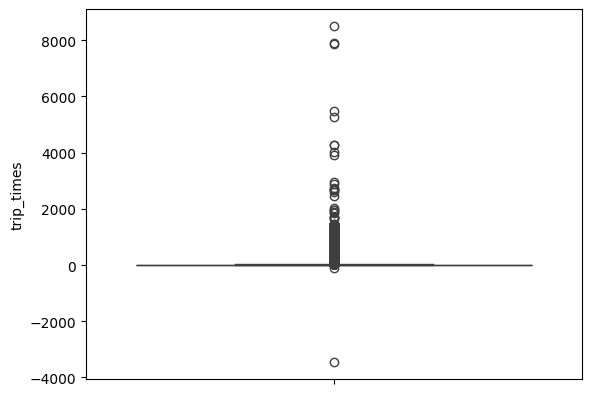

In [27]:
import seaborn as sns

# the skewed box plot shows us the presence of outliers 
sns.boxplot(y="trip_times", data =frame_with_durations)
plt.show()

In [28]:
#calculating 0-100th percentile to find a the correct percentile value for removal of outliers
for i in range(0,100,10):
    var =frame_with_durations["trip_times"].values
    var = np.sort(var,axis = None)
    print("{} percentile value is {}".format(i,var[int(len(var)*(float(i)/100))]))
print ("100 percentile value is ",var[-1])

0 percentile value is -3442.4
10 percentile value is 4.2
20 percentile value is 5.866666666666666
30 percentile value is 7.416666666666667
40 percentile value is 9.0
50 percentile value is 10.75
60 percentile value is 12.816666666666666
70 percentile value is 15.416666666666666
80 percentile value is 19.116666666666667
90 percentile value is 25.95
100 percentile value is  8513.183333333332


In [30]:
#looking further from the 99th percecntile
for i in range(90,100):
    var =frame_with_durations["trip_times"].values
    var = np.sort(var,axis = None)
    print("{} percentile value is {}".format(i,var[int(len(var)*(float(i)/100))]))
print ("100 percentile value is ",var[-1])

90 percentile value is 25.95
91 percentile value is 27.05
92 percentile value is 28.333333333333332
93 percentile value is 29.833333333333332
94 percentile value is 31.583333333333332
95 percentile value is 33.75
96 percentile value is 36.46666666666667
97 percentile value is 40.21666666666667
98 percentile value is 45.78333333333333
99 percentile value is 56.03333333333333
100 percentile value is  8513.183333333332


100 percentile value being far greater than 99 percentile value means corrupt data

0 percentile value being negative also invalid data because duration cannot be less than 1

In [31]:
#removing data based on our analysis and TLC regulations
frame_with_durations_modified=frame_with_durations[(frame_with_durations.trip_times>1) & (frame_with_durations.trip_times<720)]
     

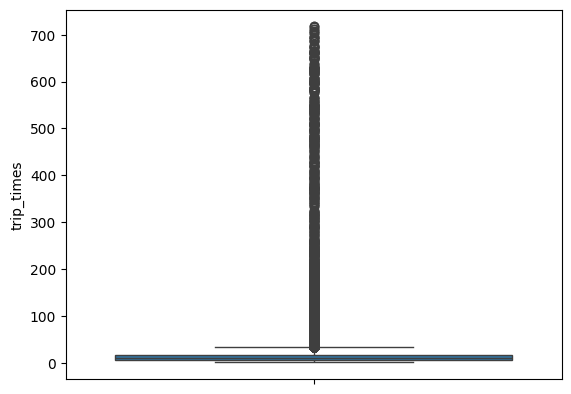

In [32]:
#box-plot after removal of outliers
sns.boxplot(y="trip_times", data =frame_with_durations_modified)
plt.show()

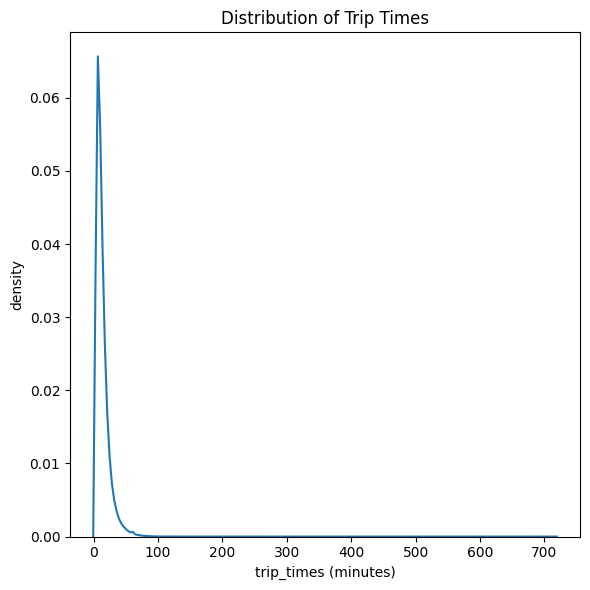

In [34]:
# pdf of trip-times after removing outliers
fig, ax = plt.subplots(figsize=(6, 6))
sns.kdeplot(frame_with_durations_modified["trip_times"], ax=ax)
ax.set_xlabel("trip_times (minutes)")
ax.set_ylabel("density")
ax.set_title("Distribution of Trip Times")
plt.tight_layout()
plt.show()


In [35]:
#converting the values to log-values to chec for log-normal
import math
frame_with_durations_modified['log_times']=[math.log(i) for i in frame_with_durations_modified['trip_times'].values]
     

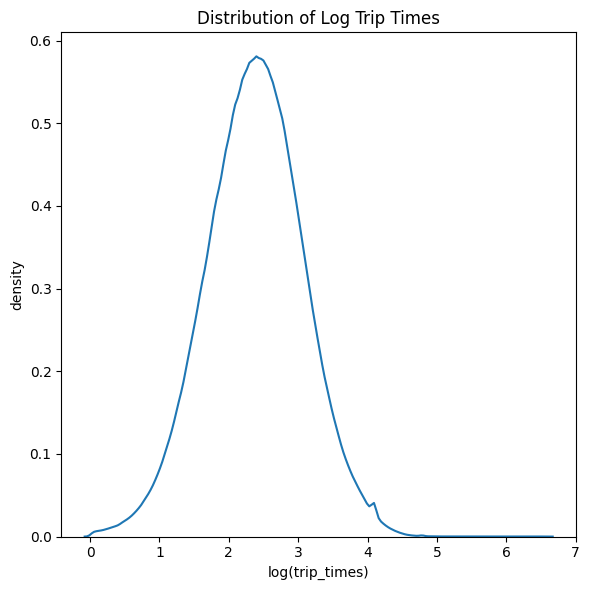

In [37]:
#pdf of log-values
fig, ax = plt.subplots(figsize=(6, 6))
sns.kdeplot(frame_with_durations_modified["log_times"], ax=ax)
ax.set_xlabel("log(trip_times)")
ax.set_ylabel("density")
ax.set_title("Distribution of Log Trip Times")
plt.tight_layout()
plt.show()


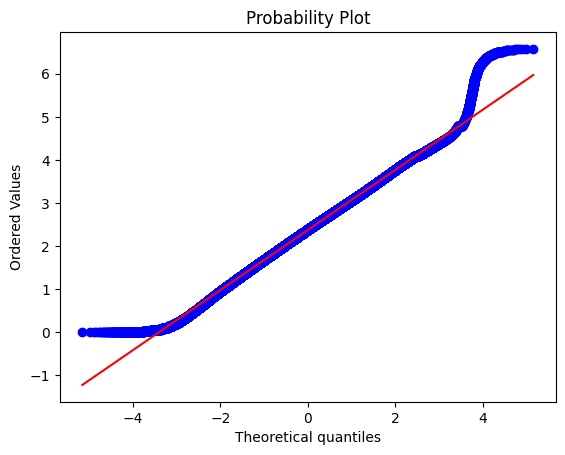

In [38]:
import scipy

#Q-Q plot for checking if trip-times is log-normal
scipy.stats.probplot(frame_with_durations_modified['log_times'].values, plot=plt)
plt.show()

### 3. Speed

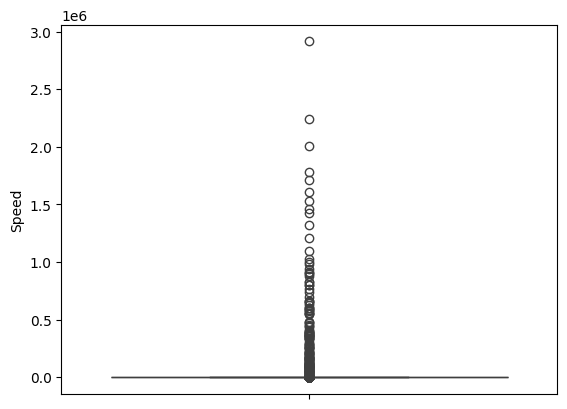

In [39]:
# check for any outliers in the data after trip duration outliers removed
# box-plot for speeds with outliers
frame_with_durations_modified['Speed'] = 60*(frame_with_durations_modified['trip_distance']/frame_with_durations_modified['trip_times'])
sns.boxplot(y="Speed", data =frame_with_durations_modified)
plt.show()

In [40]:
#calculating speed values at each percntile 0,10,20,30,40,50,60,70,80,90,100 
for i in range(0,100,10):
    var =frame_with_durations_modified["Speed"].values
    var = np.sort(var,axis = None)
    print("{} percentile value is {}".format(i,var[int(len(var)*(float(i)/100))]))
print("100 percentile value is ",var[-1])

#calculating speed values at each percntile 90,91,92,93,94,95,96,97,98,99,100
for i in range(90,100):
    var =frame_with_durations_modified["Speed"].values
    var = np.sort(var,axis = None)
    print("{} percentile value is {}".format(i,var[int(len(var)*(float(i)/100))]))
print("100 percentile value is ",var[-1])
     

0 percentile value is 0.0
10 percentile value is 6.5653498049565
20 percentile value is 7.815468230435126
30 percentile value is 8.780488153783288
40 percentile value is 9.692307252150316
50 percentile value is 10.650602593479386
60 percentile value is 11.764705882352942
70 percentile value is 13.222037014459728
80 percentile value is 15.473684511686628
90 percentile value is 20.349398004003316
100 percentile value is  2914845.703125
90 percentile value is 20.349398004003316
91 percentile value is 21.209302325581394
92 percentile value is 22.188033405532185
93 percentile value is 23.299945417707544
94 percentile value is 24.571428980146134
95 percentile value is 26.06103570855535
96 percentile value is 27.898089900897567
97 percentile value is 30.164834693237978
98 percentile value is 33.070423681411384
99 percentile value is 37.28353082627716
100 percentile value is  2914845.703125


In [41]:
#removing further outliers based on the 99.9th percentile value
frame_with_durations_modified=frame_with_durations[(frame_with_durations.Speed>0) & (frame_with_durations.Speed<37.28)] # 37.28 is the 99.9th percentile value for speed

#avg.speed of cabs in New-York
sum(frame_with_durations_modified["Speed"]) / float(len(frame_with_durations_modified["Speed"]))
     

12.071315865526945

The avg speed in Newyork speed is 12.07miles/hr, so a cab driver can travel 2 miles per 10min on avg.

### 4. Trip Distance

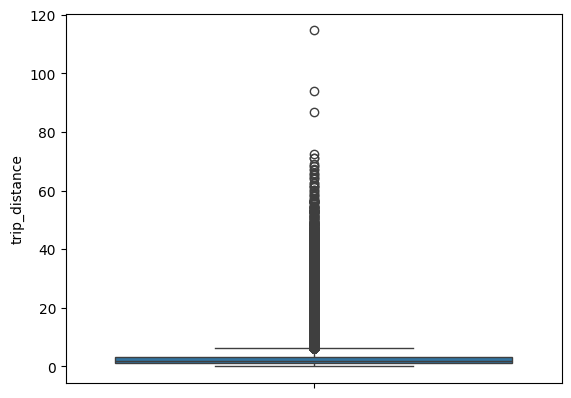

In [42]:
# up to now we have removed the outliers based on trip durations and cab speeds
# lets try if there are any outliers in trip distances
# box-plot showing outliers in trip-distance values
sns.boxplot(y="trip_distance", data =frame_with_durations_modified)
plt.show()

In [44]:
#calculating trip distance values at each percntile 0,10,20,30,40,50,60,70,80,90,100 
for i in range(0,100,10):
    var =frame_with_durations_modified["trip_distance"].values
    var = np.sort(var,axis = None)
    print("{} percentile value is {}".format(i,var[int(len(var)*(float(i)/100))]))
print("100 percentile value is ",var[-1])

#calculating trip distance values at each percntile 90,91,92,93,94,95,96,97,98,99,100
for i in range(90,100):
    var =frame_with_durations_modified["trip_distance"].values
    var = np.sort(var,axis = None)
    print("{} percentile value is {}".format(i,var[int(len(var)*(float(i)/100))]))
print("100 percentile value is ",var[-1])

0 percentile value is 0.009999999776482582
10 percentile value is 0.699999988079071
20 percentile value is 0.949999988079071
30 percentile value is 1.2000000476837158
40 percentile value is 1.4600000381469727
50 percentile value is 1.7699999809265137
60 percentile value is 2.1600000858306885
70 percentile value is 2.700000047683716
80 percentile value is 3.690000057220459
90 percentile value is 6.539999961853027
100 percentile value is  114.7
90 percentile value is 6.539999961853027
91 percentile value is 7.199999809265137
92 percentile value is 8.0
93 percentile value is 8.800000190734863
94 percentile value is 9.600000381469727
95 percentile value is 10.510000228881836
96 percentile value is 11.890000343322754
97 percentile value is 15.119999885559082
98 percentile value is 17.639999389648438
99 percentile value is 19.0
100 percentile value is  114.7


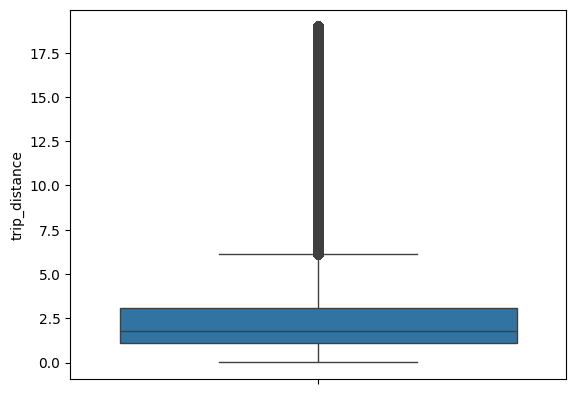

In [46]:
#removing further outliers based on the 99.9th percentile value
frame_with_durations_modified=frame_with_durations[(frame_with_durations.trip_distance>0) & (frame_with_durations.trip_distance<19.0)] # 19.0 is the 99.9th percentile value for trip distance
                                                   
                                                   #box-plot after removal of outliers
sns.boxplot(y="trip_distance", data = frame_with_durations_modified)
plt.show()

#### Total fare is not removed from outlier

If interviewer asks:

How would you handle outliers?

You can say:

I distinguish between measurement errors (e.g., negative fares, impossible speeds) and rare but valid demand spikes. Only physically impossible values are removed. Operationally significant extremes are preserved.

That shows maturity.

In [5]:
import math
import numpy as np
import pandas as pd
import dask.dataframe as dd

# ── NYC bounding box ──────────────────────────────────────────────────────────
NYC_LON_MIN, NYC_LON_MAX = -74.15, -73.7004
NYC_LAT_MIN, NYC_LAT_MAX =  40.5774,  40.9176

# ── Thresholds derived from EDA ───────────────────────────────────────────────
TRIP_TIME_MIN_MINUTES  = 1
TRIP_TIME_MAX_MINUTES  = 720    # TLC 12-hour regulation
SPEED_MIN_MPH          = 0
SPEED_MAX_MPH          = 37.28  # 99.9th percentile
DISTANCE_MIN_MILES     = 0
DISTANCE_MAX_MILES     = 19.0   # 99.9th percentile


def remove_location_outliers(df: dd.DataFrame) -> dd.DataFrame:
    """Filter out pickups outside the NYC bounding box.

    Args:
        df: Dask DataFrame with pickup_longitude and pickup_latitude columns.

    Returns:
        Filtered Dask DataFrame.
    """
    return df[
        (df.pickup_longitude > NYC_LON_MIN) &
        (df.pickup_longitude < NYC_LON_MAX) &
        (df.pickup_latitude  > NYC_LAT_MIN) &
        (df.pickup_latitude  < NYC_LAT_MAX)
    ]


def add_trip_features(df: dd.DataFrame) -> pd.DataFrame:
    """Compute trip_times (minutes), pickup_times (unix), and Speed (mph).

    Args:
        df: Dask DataFrame with tpep_pickup_datetime, tpep_dropoff_datetime,
            trip_distance, pickup_longitude, pickup_latitude columns.

    Returns:
        Pandas DataFrame with original columns plus trip_times, pickup_times,
        Speed, and log_times.
    """
    duration = df[["tpep_pickup_datetime", "tpep_dropoff_datetime"]].compute()
    pickup_unix = [pd.Timestamp(x).timestamp() for x in duration["tpep_pickup_datetime"].values]
    drop_unix   = [pd.Timestamp(x).timestamp() for x in duration["tpep_dropoff_datetime"].values]

    result = df[["passenger_count", "trip_distance", "pickup_longitude",
                 "pickup_latitude", "total_amount"]].compute()
    result["trip_times"]   = (np.array(drop_unix) - np.array(pickup_unix)) / 60.0
    result["pickup_times"] = pickup_unix
    result["Speed"]        = 60 * (result["trip_distance"] / result["trip_times"])
    result["log_times"]    = result["trip_times"].apply(lambda x: math.log(x) if x > 0 else float("nan"))
    return result


def remove_trip_time_outliers(
    df: pd.DataFrame,
    min_minutes: float = TRIP_TIME_MIN_MINUTES,
    max_minutes: float = TRIP_TIME_MAX_MINUTES,
) -> pd.DataFrame:
    """Remove rows with trip durations outside [min_minutes, max_minutes].

    Args:
        df: Pandas DataFrame with a trip_times column.
        min_minutes: Lower bound in minutes.
        max_minutes: Upper bound in minutes (TLC cap = 720).

    Returns:
        Filtered DataFrame.
    """
    return df[(df.trip_times > min_minutes) & (df.trip_times < max_minutes)]


def remove_speed_outliers(
    df: pd.DataFrame,
    min_speed: float = SPEED_MIN_MPH,
    max_speed: float = SPEED_MAX_MPH,
) -> pd.DataFrame:
    """Remove rows with Speed outside [min_speed, max_speed] mph.

    Args:
        df: Pandas DataFrame with a Speed column.
        min_speed: Lower bound (mph).
        max_speed: Upper bound — 99.9th percentile from EDA (37.28 mph).

    Returns:
        Filtered DataFrame.
    """
    return df[(df.Speed > min_speed) & (df.Speed < max_speed)]


def remove_distance_outliers(
    df: pd.DataFrame,
    min_dist: float = DISTANCE_MIN_MILES,
    max_dist: float = DISTANCE_MAX_MILES,
) -> pd.DataFrame:
    """Remove rows with trip_distance outside [min_dist, max_dist] miles.

    Args:
        df: Pandas DataFrame with a trip_distance column.
        min_dist: Lower bound (miles).
        max_dist: Upper bound — 99.9th percentile from EDA (19.0 miles).

    Returns:
        Filtered DataFrame.
    """
    return df[(df.trip_distance > min_dist) & (df.trip_distance < max_dist)]


def run_outlier_pipeline(df: dd.DataFrame) -> pd.DataFrame:
    """Run the full outlier removal pipeline.

    Steps:
        1. Remove pickups outside the NYC bounding box (Dask, lazy).
        2. Compute trip features: duration, unix pickup time, speed, log_times.
        3. Remove trip time outliers (< 1 min or > 720 min).
        4. Remove speed outliers (> 37.28 mph).
        5. Remove trip distance outliers (> 19.0 miles).

    Args:
        df: Dask DataFrame from the bronze parquet with pickup coordinates
            already mapped via add_pickup_coords().

    Returns:
        Clean pandas DataFrame ready for feature engineering.
    """
    df = add_pickup_coords(df, SHP_PATH)
    # df = add_trip_features(df)
    df = remove_location_outliers(df)
    # df = remove_trip_time_outliers(df)
    # df = remove_speed_outliers(df)
    # df = remove_distance_outliers(df)
    return df


# ── Run ───────────────────────────────────────────────────────────────────────
clean_df = run_outlier_pipeline(month)
print(f"Rows after outlier removal: {len(clean_df):,}")
clean_df.head()


/home/jason/NewYorkTaxiDemandForecasting/.venv/lib/python3.13/site-packages/dask/dataframe/dask_expr/_collection.py:4218: UserWarning: 
You did not provide metadata, so Dask is running your function on a small dataset to guess output types. It is possible that Dask will guess incorrectly.
To provide an explicit output types or to silence this message, please provide the `meta=` keyword, as described in the map function that you are using.
  Before: .map(func)
  After:  .map(func, meta=('pulocationid', 'float64'))

  warnings.warn(meta_warning(meta, method="map"))
/home/jason/NewYorkTaxiDemandForecasting/.venv/lib/python3.13/site-packages/dask/dataframe/dask_expr/_collection.py:4218: UserWarning: 
You did not provide metadata, so Dask is running your function on a small dataset to guess output types. It is possible that Dask will guess incorrectly.
To provide an explicit output types or to silence this message, please provide the `meta=` keyword, as described in the map function that yo

Rows after outlier removal: 5,376,956


,vendorid,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,ratecodeid,store_and_fwd_flag,pulocationid,dolocationid,payment_type,...,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee,pickup_longitude,pickup_latitude
0,2,2022-01-01 00:00:08,2022-01-01 00:14:14,1,7.94,1,N,138,255,1,...,0.5,0.5,4.86,0.0,0.3,30.410000,0.0,1.25,-73.873629,40.774376
1,2,2022-01-01 00:00:11,2022-01-01 00:14:29,1,5.55,1,N,132,215,2,...,0.5,0.5,0.00,0.0,0.3,20.049999,0.0,1.25,-73.786535,40.646987
2,2,2022-01-01 00:00:17,2022-01-01 00:31:04,1,3.86,1,N,170,68,1,...,0.5,0.5,4.76,0.0,0.3,28.559999,2.5,0.0,-73.978492,40.747746
3,2,2022-01-01 00:00:18,2022-01-01 00:13:27,1,3.37,1,N,79,209,1,...,0.5,0.5,3.36,0.0,0.3,20.160000,2.5,0.0,-73.985937,40.727620
4,2,2022-01-01 00:00:20,2022-01-01 00:20:51,1,4.89,1,N,68,256,1,...,0.5,0.5,6.54,0.0,0.3,28.340000,2.5,0.0,-73.999917,40.748428
